# Fitting and Solving Linear Equations

## Exercise 1

![](rescap.png)

Consider the above circuit. Suppose the voltage $V_+$ is time-varying and sinusoidal of the form $V_+ = x_+ \exp(i \omega t)$ with $x_+$ a constant.

The resistors in the circuit can be treated using Ohm's law.
For the capacitors the charge $Q$ and voltage $V$ across them are related by the capacitor law $Q=CV$, where $C$ is the capacitance.
Differentiating both sides of this expression gives the current $I$ flowing in on one side of the capacitor and out on the other:
\begin{equation}
  I = \frac{dQ}{dt} = C \frac{dV}{dt}.
\end{equation}
Now assume the voltages at the points labeled 1, 2, and 3 are of the form $V_1 = x_1 \exp(i \omega t)$, $V_2 = x_2 \exp(i \omega t)$, and $V_3 = x_3 \exp(i \omega t)$.
If you add up the currents using Kirchoff's law that at a junction the sum of the currents in equals the sum of the currents out, you can find that the constants $x_1$,
$x_2$, and $x_3$ satisfy the equations
\begin{align*}
  \left( {1\over R_1} + {1\over R_4} + i\omega C_1 \right) x_1 - i\omega C_1 x_2
  & = {x_+\over R_1}\,, \\
  - i\omega C_1 x_1 + \left( {1\over R_2} + {1\over R_5} + i\omega C_1 + i\omega C_2 \right) x_2 - i\omega C_2 x_3
                                                                                           & = {x_+\over R_2}\,, \\
  - i\omega C_2 x_2 + \left( {1\over R_3} + {1\over R_6} + i\omega C_2 \right) x_3
  & = {x_+\over R_3}\,.
\end{align*}
This is a linear system of equations for three complex numbers, $x_1$, $x_2$, and $x_3$.

We will be solving the above linear system of equations in the form $A x = b$, where $x$ is the vector $(x_1 x_2 x_3$ and $b$ is the vector composed of the right-hand sides of the equations above.

(a) Write a function that takes as input the list of resistance values ($R_1$ to $R_6$) and the list of capacitances ($C_1$ and $C_2$), and returns (as numpy.array) the matrix $A$. Note: the matrix for this problem will have complex elements; your function should be able to work with real or complex arguments.

In [43]:
import numpy as np
R = [1e3, 2e3, 1e3, 2e3, 1e3, 2e3]
omega = 1e3 
C = [1e-6 *omega * 1j, 5e-7*omega*1j]
xplus = 3.0
  

In [44]:
import numpy as np
def CircuitMatrix(R_, C_):
  
   # R_ [float]: list of resistors R1 to R5
    #C_ [complex]: list of capacitances C1 and C2
   
    A = np.empty((3, 3), complex)

    A[0, 0] = 1./R[0] + 1./R[3] + C[0]
    A[0, 1] = -C[0]
    A[0, 2] = 0.

    A[1, 0] = -C[0]
    A[1, 1] = 1./R[1] + 1./R[4] + C[1]
    A[1, 2] = -C[1]

    A[2, 0] = 0.
    A[2, 1] = -C[1]
    A[2, 2] = 1./R[2] + 1./R[5] + C[1]
    

    return A

A=CircuitMatrix(R, C)

In [46]:
print(A)

[[ 0.0015+0.001j  -0.    -0.001j   0.    +0.j    ]
 [-0.    -0.001j   0.0015+0.0005j -0.    -0.0005j]
 [ 0.    +0.j     -0.    -0.0005j  0.0015+0.0005j]]


(b) Write a function that takes as input the list of resistance values and the value of $x+$, and returns (as numpy.array) the vector $b$.

In [55]:
def RHS(R, xplus):
    return xplus*np.array([1./R[0], 1./R[1], 1./R[2]], complex)

(c) Use your functions from parts (a) and (b) to construct the linear system, and use numpy.linalg.solve to solve for $x_1$, $x_2$, and $x_3$ with:
    \begin{align*}
      R_1 &= R_3 = R_5 = 1\,\mathrm{k}\Omega, \\
      R_2 &= R_4 = R_6 = 2\,\mathrm{k}\Omega, \\
      C_1 &= 1\,\mu\mathrm{F},\qquad C_2 = 0.5\,\mu\mathrm{F}, \\
      x_+ &= 3\,\mathrm{V},\qquad \omega = 1000~\text{rad/s}.
    \end{align*}

Have your program calculate and print the amplitudes of the three voltages $|V_1|$, $|V_2|$, and $|V_3|$ and their phases (i.e. the phases of the coefficients $x_1, x_2, x_3$) at $t=0$ in degrees. *Hint: numpy.angle() will compute the phase of a complex number for you.*

In [76]:
v = RHS(R, xplus)
print(v)

[0.003 +0.j 0.0015+0.j 0.003 +0.j]


In [77]:
X = np.linalg.solve(A,v)

In [78]:
print("Amplitudes and phases of voltages:")
for i in range(3):
    print ("|V{0}| = {1:.2e} V, phi{0}(t=0) = {2} degrees" .format(
           i+1, abs(X[i]), int(np.angle(X[i], deg=True))))

Amplitudes and phases of voltages:
|V1| = 1.56e+00 V, phi1(t=0) = -4 degrees
|V2| = 1.50e+00 V, phi2(t=0) = 21 degrees
|V3| = 2.81e+00 V, phi3(t=0) = 14 degrees


(d) Plot the (real) voltages $|V_1|$, $|V_2|$, and $|V_3|$ as a function of time for two periods
of the oscillations. You should have 3 lines on the same plot, with labelled axes and a nice legend.

*Hint: about 256 points should be enough to obtain a nice plot.*

|V1| = 1.34e+00 V, phi1(t=0) = 0 degrees
|V2| = 1.68e+00 V, phi2(t=0) = 36 degrees
|V3| = 1.64e+00 V, phi3(t=0) = -3 degrees


<function __main__.plotVoltages(X_in, omega_in)>

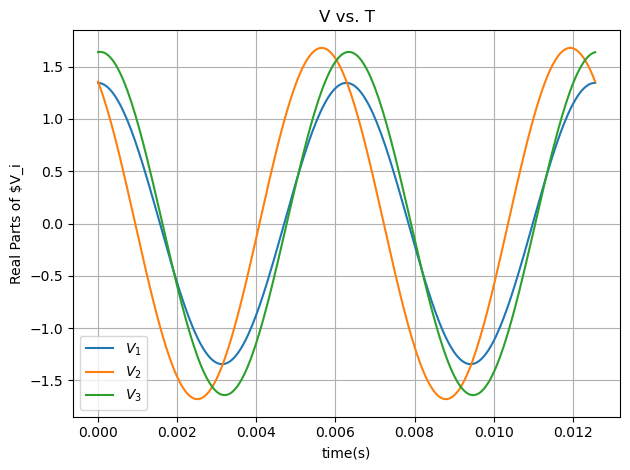

In [68]:
import matplotlib.pyplot as plt

def plotVoltages(X_in, omega_in):
    duration = 4.* np.pi/omega_in
    t= np.linspace(0., duration, 256)
    for i in range(3):
        print ("|V{0}| = {1:.2e} V, phi{0}(t=0) = {2} degrees" .format(
           i+1, abs(X[i]), int(np.angle(X[i], deg=True))))
    V1 = np.real(X_in[0] * np.exp(1j*omega_in*t))
    V2 = np.real(X_in[1] * np.exp(1j*omega_in*t))
    V3 = np.real(X_in[2] * np.exp(1j*omega_in*t))
    
    plt.figure()
    plt.plot(t, V1, label='$V_1$')
    plt.plot(t, V2, label='$V_2$')
    plt.plot(t, V3, label='$V_3$')
    plt.xlabel('time(s)')
    plt.ylabel(r'Real Parts of $V_i')
    plt.title(r'V vs. T')
    plt.grid()
    plt.legend()
    plt.tight_layout()
    plt.show
    return plotVoltages

plotVoltages(X, omega)


(e) Now replace the resistor $R_6$ with an inductor $L$.
Set $R_6 = 2$ k$\Omega$, $\omega = 1000$ rad/s , and $L=R_6/\omega = 2$ H, where H is the Henries unit of inductance.

Again, print and calculate the amplitudes and phases of $V_1$, $V_2$, and $V_3$ at $t=0$, and then plot $V_1$, $V_2$ and $V_3$ as a function of time for two periods of the oscillation.

Briefly describe the impact of replacing the resistor $R_6$ by the imaginary impedance of the same magnitude, $i R_6$.

In [72]:
def CircuitMatrixInductor(element, R, C):
    """ I define the matrix A as a function of the one element we turn from a
    resistor to an inductor
    IN: element [complex]: the resistor or inductor
    R_ [float]: list of resistors R1 to R5
    C_ [complex]: list of capacitances C1 and C2
    """
    A = np.empty((3, 3), complex)
    A[0, 0] = 1./R[0] + 1./R[3] + C[0]
    A[0, 1] = -C[0]
    A[0, 2] = 0.

    A[1, 0] = -C[0]
    A[1, 1] = 1./R[1] + 1./R[4] + C[0] + C[1]
    A[1, 2] = -C[1]

    A[2, 0] = 0.
    A[2, 1] = -C[1]
    A[2, 2] = 1./R[2] + 1./element + C[1]
    
    ...

    return A
A_inductor= A


[0.003 +0.j 0.0015+0.j 0.003 +0.j]
Amplitudes and phases of voltages:
|V1| = 1.56e+00 V, phi1(t=0) = -4 degrees
|V2| = 1.50e+00 V, phi2(t=0) = 21 degrees
|V3| = 2.81e+00 V, phi3(t=0) = 14 degrees
|V1| = 1.56e+00 V, phi1(t=0) = -4 degrees
|V2| = 1.50e+00 V, phi2(t=0) = 21 degrees
|V3| = 2.81e+00 V, phi3(t=0) = 14 degrees


<function __main__.plotVoltages(X_in, omega_in)>

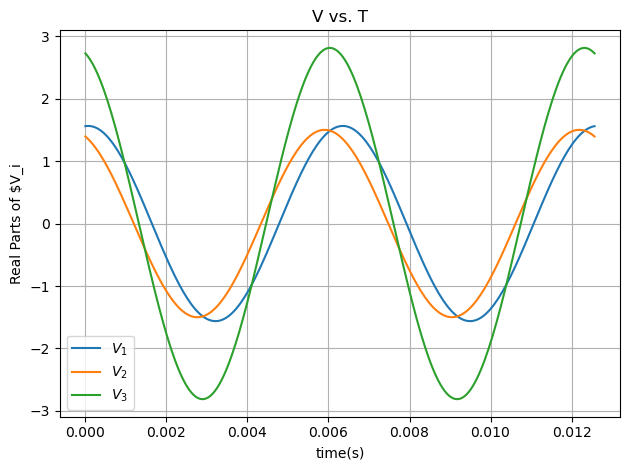

In [81]:
Lomega = 2e3
 #omega  # [ohms]
A_inductor = CircuitMatrixInductor(1j*Lomega, R, C)
X_inductor = np.linalg.solve(A_inductor, v)
v = RHS(R, xplus)
print(v)
X= np.linalg.solve(A_inductor,v)
print("Amplitudes and phases of voltages:")
for i in range(3):
    print ("|V{0}| = {1:.2e} V, phi{0}(t=0) = {2} degrees" .format(
           i+1, abs(X[i]), int(np.angle(X[i], deg=True))))
# pass 1j*omega*L as the element argument to CircuitMatrixInductor
plotVoltages(X_inductor, omega)

## Exercise 2

![Exercise2 circuit](resistor-chain.png)

Ohm’s law and the Kirchhoff current law, which says that the total net current flow out of (or into) any junction in a circuit must be zero, show that the voltages $V_1 \dots V_N$
satisfy the equations:
$$ 3V_1 − V_2 − V_3 = V_+ $$

Ohm’s law and the Kirchhoff current law, which says that the total net current flow out of (or into) any junction in a circuit must be zero, show that the voltages $V_1 \dots V_N$
satisfy the equations:
$$ \begin{eqnarray}
3V_1 − V_2 − V_3 &=& V_+ \\ 
 −V_1 + 4V_2 − V_3 − V_4 &=& V_+ \\ 
\dots \\ 
−V_{i−2} − V_{i−1} + 4V_i − V_{i+1} − V_{i+2} &=& 0 \\ 
\dots 
−V_{N−3} − V_{N−2} + 4V_{N−1} − V_N &=& 0 \\ 
−V_{N−2} − V_{N−1} + 3V_N &=& 0. 
\end{eqnarray}$$

We will express these equations in vector form $Cv = w$.

a) Write functions to create $C$ and $w$, given that there are $N$ internal junctions. 

In [44]:
import numpy as np
def anotherCircuitMatrix(N_in):
    A = np.zeros([N_in, N_in], float)
    diagonal = np.ones(N_in, float) *4.0
    diagonal[0] = 3.0 
    diagonal[N_in-1] = 3.0 
    A+= np.diag(diagonal)
    minusOnes = np.ones(N_in-1, float)* -1.0
    A+= np.diag(minusOnes, 1)
    A+= np.diag(minusOnes, -1)
    minusOnes = np.ones(N_in-2, float)* -1.0
    A+= np.diag(minusOnes, 2)
    A+= np.diag(minusOnes, -2)
    return A

In [45]:
def wRHS(N_in, v_in=5.0):
    RHS = np.zeros(N_in, float)
    RHS[0] = v_in
    RHS[1] = v_in
    return RHS



b) Create the system and use numpy.linalg.solve to solve for $v$, with $N=6$. *Hint: All the voltage values should lie between zero and 5V. If they don’t, something is wrong.*

c) $N=100$ may crash your laptop or Syzygy, so... run it on the Teach cluster. Remember, you need to convert your notebook to a .py script, and also create a batch script to run it!

d) For a much higher $N$, the standard numpy.linalg.solve function will probably crash even on the Teach cluster. So, we need to make use of the fact that the matrix $A$ is banded, and use a special technique to solve it. Try the following code with N=1000 (yes, it should run fine on your laptop or Syzygy.)

In [59]:
from scipy.linalg import solve_banded
c = anotherCircuitMatrix(6)
print(c)

[[ 3. -1. -1.  0.  0.  0.]
 [-1.  4. -1. -1.  0.  0.]
 [-1. -1.  4. -1. -1.  0.]
 [ 0. -1. -1.  4. -1. -1.]
 [ 0.  0. -1. -1.  4. -1.]
 [ 0.  0.  0. -1. -1.  3.]]


In [54]:
def bandedCircuitMatrix(N_in):
    ab = np.zeros([5,N_in], float)
    
    # All diagonal elements = 4, except first and last which are 3
    diagonal = np.ones(N_in, float) * 4.0
    diagonal[0] = 3.0
    diagonal[N_in-1] = 3.0
    ab[2] = diagonal

    # the two upper and two lower off-diagonals
    offdiag1 = np.ones(N_in, float) * -1.0
    ab[0] = offdiag1
    ab[1] = offdiag1
    ab[3] = offdiag1
    ab[4] = offdiag1
    
    return ab

In [58]:

C=bandedCircuitMatrix(6)
w=wRHS(6)
solve_banded((2,2),C,w)
print(C)

[[-1. -1. -1. -1. -1. -1.]
 [-1. -1. -1. -1. -1. -1.]
 [ 3.  4.  4.  4.  4.  3.]
 [-1. -1. -1. -1. -1. -1.]
 [-1. -1. -1. -1. -1. -1.]]


In [ ]:
C=bandedCircuitMatrix(50)
w=wRHS(50)
solve_banded((2,2),C,w)
print(C)
print(w)
# I did with 3000 as seen in the attached file 

[[-1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.
  -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.
  -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.]
 [-1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.
  -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.
  -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.]
 [ 3.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.
   4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.
   4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  3.]
 [-1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.
  -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.
  -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.]
 [-1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.
  -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.
  -1. -1. -1. -1. -1. -1

e) BONUS: try the banded code from the previous part on the cluster, with a really really big N. (Note: with N large enough, you may eventually over-run your job's memory allocation)